# Projet Python
## Calcul scientifique: Optimisation et classification de données

Choisissez un problème de classification binaire :

- `main-pied` : `hand` vs `foot` ;
- `pingouin-perroquet` : `penguin` vs `parrot` ;
- `oignon-ananas` : `onion` vs `pineapple`.

La première classe porte l'étiquette $0$, la seconde l'étiquette $1$.

L'objectif est de programmer vous-mêmes une régression logistique, son gradient, une descente à pas fixe puis une recherche linéaire d'Armijo. `scikit-learn` ne sera utilisé comme classifieur qu'à la fin, pour comparaison.

Les données proviennent du **Quick, Draw! Dataset** de Google Creative Lab (licence CC BY 4.0). Les fonctions de téléchargement sont fournies.



In [137]:
# À exécuter UNE SEULE FOIS si PyQt5 n'est pas disponible :
%pip install -U PyQt5

# Dans Jupyter, cette commande intègre la boucle événementielle Qt au notebook.
# La fenêtre de dessin reste interactive sans bloquer l'exécution des cellules.
%gui qt5

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\dorut\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [138]:
## PACKAGES 

import json
import time
import urllib.parse
import urllib.request
from pathlib import Path
import importlib
import numpy as np
import random

#%matplotlib widget
%gui qt5
import matplotlib.pyplot as plt
from PIL import Image

#from sklearn.model_selection import train_test_split
#from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score, log_loss)

from dessin_process import *
from dessin_viewer import *

#importlib.reload(dessin_process)
#importlib.reload(dessin_viewer)

# Même architecture que dans le TP2 :
# - dessin_process.py : calculs et traitements d'images ;
# - dessin_viewer.py  : interface graphique Qt.


RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


### 1. Question préambule:
Commencez par classer intuitivement les trois couples du plus facile au plus difficile pour un humain. Vous reviendrez sur cette réponse à la fin du projet.

### 2.1 Choix du couple
choisissez l'un des couples via la variable $\texttt{PAIR}$. Chargez un nombre identique de dessins $\texttt{N\_PER\_CLASS}$ pour chaque classe. Puis créez un dictionnaire python via la variable $\texttt{PAIRS}$. Un dictionnaire permet d'associer à des clés des valeurs. Dans notre cas: Clé = "main-pied", "pingouin-perroquet" et "oignon-ananas". Valeurs =("hand", "foot", "main", "pied"),("penguin", "parrot", "pingouin", "perroquet") et ("onion", "pineapple", "oignon", "ananas").



Une image en niveaux de gris codée sur 8 bits par pixel utilise un octet par pixel. Chaque pixel est représenté par une valeur entière comprise entre 0 et 255. L’image peut alors être manipulée comme un tableau NumPy uint8 à deux dimensions : la première dimension correspond à la hauteur et la seconde à la largeur.

Complétez $\texttt{compute\_centering\_parameters}$ et $\texttt{image\_converter}$ du module $\texttt{dessin\_process}$ ainsi que les fonctions $\texttt{paint\_disk}$ et $\texttt{paint\_segment}$


In [139]:
## 1/ Choisissez votre problème ici

PAIR = ("pingouin-perroquet")  # "main-pied", "pingouin-perroquet", "oignon-ananas"
N_PER_CLASS = 1000

PAIRS = {
    "main-pied": ("hand", "foot", "main", "pied"),
    "pingouin-perroquet": ("penguin", "parrot", "pingouin", "perroquet"),
    "oignon-ananas": ("onion", "pineapple", "oignon", "ananas")
}

cat0, cat1, nom0, nom1 = PAIRS[PAIR]
print(f"Problème choisi : {nom0} (Étiquette 0) / {nom1} (Étiquette 1)")


Problème choisi : pingouin (Étiquette 0) / perroquet (Étiquette 1)


#### Fonction $\texttt{paint\_disk}$

Le point `(x, y)` représente le centre du disque, avec `x` correspondant à la colonne et `y` à la ligne. Le disque est de rayon `radius`.
Un pixel de coordonnées `(i, j)` appartient au disque si


$(i-y)^2+(j-x)^2 \leq \texttt{radius}^2.$

Les pixels appartenant au disque devront recevoir la valeur `1` (=blanc).

#### Fonction $\texttt{paint\_segment}$

Les positions successives de la souris peuvent être relativement éloignées lorsque l'utilisateur dessine rapidement. Dessiner uniquement un disque à chaque position provoquerait alors des trous dans le trait.

Complétez la fonction ``` paint_segment(bitmap, p0, p1, radius)```

qui relie deux points $p_0=(x_0,y_0)
\quad\text{et}\quad
p_1=(x_1,y_1)$ par un trait continu.

Pour cela :

1. calculez la distance entre `p0` et `p1` ;
2. choisissez un nombre suffisant de points intermédiaires entre ces deux positions ;
3. utilisez `np.linspace` pour interpoler leurs coordonnées ;
4. appelez `paint_disk` en chacun de ces points.

Attention: Le pas entre deux centres successifs doit être suffisamment petit par rapport au rayon du pinceau pour que les disques se chevauchent et forment un trait continu.


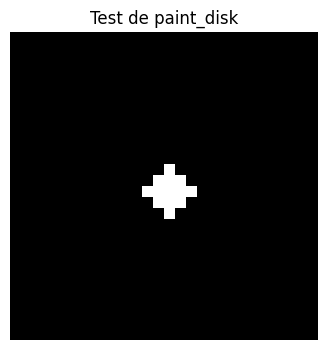

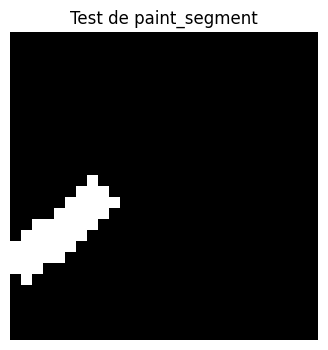

In [140]:
test_paint_disk()
test_paint_segment()

In [141]:
# =================================================================
# TÉLÉCHARGEMENT ET PRÉPARATION DES DONNÉES QUICKDRAW 
# =================================================================
#
# Les traitements d'image sont dans dessin_process.py :
#   - compute_centering_parameters(...)
#   - paint_disk(...)
#   - paint_segment(...)
#   - image_converter(...)
#

BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/"
CACHE_DIR = Path("quickdraw_cache")
CACHE_DIR.mkdir(exist_ok=True)


def load_quickdraw_category(category, n_samples=1200, force=False):
    """Charge ``n_samples`` dessins QuickDraw d'une catégorie.

    Les dessins vectoriels lus dans le fichier NDJSON sont convertis en
    bitmaps 28 x 28 par ``dessin_process.image_converter`` puis mis en cache.
    """
    cache = CACHE_DIR / f"{category}_{n_samples}.npy"

    if cache.exists() and not force:
        return np.load(cache)

    url = BASE_URL + urllib.parse.quote(category) + ".ndjson"
    print(f"Téléchargement d'un sous-ensemble de '{category}'...")

    images = []

    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            for line in response:
                record = json.loads(line.decode("utf-8"))

                # Conversion vectoriel -> bitmap assurée par dessin_process.py.
                images.append(image_converter(record["drawing"]))

                if len(images) >= n_samples:
                    break

    except Exception as exc:
        raise RuntimeError(
            "Impossible de télécharger QuickDraw. Vérifiez la connexion internet. "
            "Une fois les fichiers mis en cache, les séances suivantes peuvent "
            "être faites hors ligne."
        ) from exc

    arr = np.stack(images)
    np.save(cache, arr)
    return arr




def load_pair(pair=PAIR, n_per_class=N_PER_CLASS):
    """Charge les deux catégories correspondant au problème choisi."""
    c0, c1, n0, n1 = PAIRS[pair]

    A = load_quickdraw_category(c0, n_per_class)
    B = load_quickdraw_category(c1, n_per_class)

    Ximg = np.concatenate([A, B], axis=0)
    y = np.concatenate([
        np.zeros(len(A), dtype=int),
        np.ones(len(B), dtype=int)
    ])

    idx = rng.permutation(len(y))
    return Ximg[idx], y[idx], (n0, n1)










### 2.1 Choix du couple et chargement

Chargez les données.


In [142]:
# TODO — charger les données

Ximg, y, class_names = load_pair(PAIR, N_PER_CLASS)

print("Images :", Ximg.shape)
print("Etiquettes :", y.shape)
print("Effectifs :", np.bincount(y))
print("Classes :", class_names)

Images : (2000, 28, 28)
Etiquettes : (2000,)
Effectifs : [1000 1000]
Classes : ('pingouin', 'perroquet')


### 2.2 Premières visualisations
Affichez au moins 16 dessins de chaque classe à l'aide de matplotlib

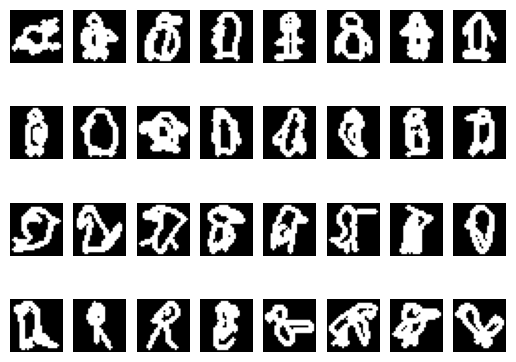

In [143]:
# TODO — afficher au moins 16 exemples de chaque classe



fig, axes = plt.subplots(4, 8)

for classe in range(2):

    indices = np.where(y == classe)[0]

    for i in range(16):

        ligne = 2 * classe + i // 8
        colonne = i % 8

        axes[ligne, colonne].imshow(Ximg[indices[i]], cmap="gray")
        axes[ligne, colonne].axis("off")

plt.show()







### 2.3 Images moyennes

Calculez $\bar x_0$, $\bar x_1$ et $\bar x_1-\bar x_0$. Commentez les zones qui différencient les classes.


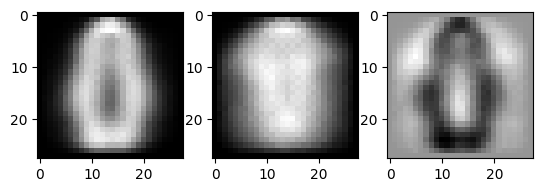

In [144]:
# TODO — images moyennes et différence
fig, axes = plt.subplots(1,3)
x0_moy = Ximg[y==0].mean(axis = 0)
axes[0].imshow(x0_moy, cmap="gray")

x1_moy = Ximg[y==1].mean(axis = 0)
axes[1].imshow(x1_moy, cmap="gray")

diff = x1_moy-x0_moy
axes[2].imshow(diff, cmap="gray")

### 2.4 Prétraitement et séparation apprentissage/test

Normalisez les pixels dans $[0,1]$, aplatissez chaque image en un vecteur de dimension 784 puis conservez 70 % des données pour l'apprentissage et 30 % pour le test.



In [145]:
# TODO
X = Ximg.astype(float) / 255

# Aplatir les images
X = X.reshape(len(X), 784)

# Coder train_test_split
def train_test_split(X, y, test_size=0.3):

    X_train = []
    X_test = []
    y_train = []
    y_test = []

    np.random.seed(1)

    # Mélanger les indices
    indices = np.random.permutation(len(X))

    # Nombre d'images pour le test
    n_test = int(np.ceil(len(X) * test_size))

    # Construire le jeu de test
    for i in range(n_test):
        j = indices[i]

        X_test.append(X[j])
        y_test.append(y[j])

    # Construire le jeu d'apprentissage
    for i in range(n_test, len(X)):
        j = indices[i]

        X_train.append(X[j])
        y_train.append(y[j])

    return (np.array(X_train), np.array(X_test),
            np.array(y_train), np.array(y_test))


# Séparer les données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

print(X_train.shape, X_test.shape)
""" 
# Normalisation
X = Ximg.astype(float) / 255

# Aplatir les images en vecteurs de dimension 784
X = X.reshape(len(X), 784)
# Codons train_test_split
def train_test_split(X, y, test_size=0.3):
    X_train=[]
    X_test=[]
    y_train=[]
    y_test=[]
    np.random.seed(1)
    X= random.shuffle(X)#melanger X
    y= random.shuffle(y)#melanger y
    for i in range(np.ceil(len(X)*test_size)):
        X_test.append(X[i])
    for i in range(np.ceil(len(X)*test_size), len(X)):
        X_train.append(X[i])
    for i in range(np.ceil(len(y)*test_size)):
        y_test.append(y[i])
    for i in range(np.ceil(len(y)*test_size), len(y)):
            y_train.append(y[i])


    return X_train, X_test, y_train, y_test

# Séparer les données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

print(X_train.shape, X_test.shape)"""



(1400, 784) (600, 784)


' \n# Normalisation\nX = Ximg.astype(float) / 255\n\n# Aplatir les images en vecteurs de dimension 784\nX = X.reshape(len(X), 784)\n# Codons train_test_split\ndef train_test_split(X, y, test_size=0.3):\n    X_train=[]\n    X_test=[]\n    y_train=[]\n    y_test=[]\n    np.random.seed(1)\n    X= random.shuffle(X)#melanger X\n    y= random.shuffle(y)#melanger y\n    for i in range(np.ceil(len(X)*test_size)):\n        X_test.append(X[i])\n    for i in range(np.ceil(len(X)*test_size), len(X)):\n        X_train.append(X[i])\n    for i in range(np.ceil(len(y)*test_size)):\n        y_test.append(y[i])\n    for i in range(np.ceil(len(y)*test_size), len(y)):\n            y_train.append(y[i])\n\n\n    return X_train, X_test, y_train, y_test\n\n# Séparer les données\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)\n\nprint(X_train.shape, X_test.shape)'

## 3. Construire le classifieur! 
On pose
$$
P(y=1\mid x)=\sigma(w^T x+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

On absorbe le biais en ajoutant une colonne de 1 aux données via $\texttt{add\_bias}$.

### 3.1 Score linéaire et sigmoïde
Programmez $\texttt{sigmoid(z)}$ et tracez cette fonction.



(1400, 784)


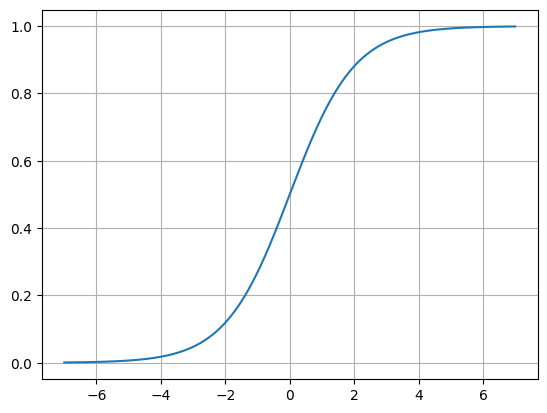

In [146]:
def add_bias(X):
    X_1 = np.zeros((X.shape[0], X.shape[1] + 1))
    X_1[:, 0:X.shape[1]] = X
    X_1[:, -1] = np.ones(X.shape[0])
    return X_1


def sigmoid(z):
    return 1/(1+np.exp(-z))

print(X_train.shape)

X_train_b = add_bias(X_train)
X_test_b = add_bias(X_test)
absc = np.linspace(-7,7,1000)
ord = sigmoid(absc)
plt.grid()
plt.plot(absc, ord)




### 3.2 Log-loss régularisée
Complétez le code.
    
$$
f(\theta)=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
+\frac{\lambda}{2}\|w\|^2.
$$

Le biais n'est pas régularisé.

**Questions.** Quelle contribution donne une observation de classe $1$ lorsque le modèle prédit $p_i=0.99$ ? Et lorsque le modèle prédit $p_i=0.01$ ? Comparez qualitativement.

**Question.** Pourquoi la log-loss pénalise-t-elle fortement une prédiction très confiante mais fausse ?

**Question.** Quel est le rôle de $\lambda$ ? Que devrait devenir la norme de $w$ lorsque $\lambda$ augmente ?

**Question.** Pourquoi choisit-on ici de ne pas régulariser le biais $b$ ?

### 3.3 Gradient
On veut montrer que, sans régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y), 
$$
et avec régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y)
+\lambda\begin{pmatrix}w\\0\end{pmatrix}.
$$

**Exercice.** Retrouvez les formules ci-dessus en utilisant $\sigma'(z)=\sigma(z)(1-\sigma(z))$.

Vérifiez soigneusement les dimensions de toutes les quantités dans l'expression matricielle du gradient.
Complétez le code ci-dessous.


In [147]:
"""def objective(theta, Xb, y, lmbda=1e-2):
    n=len(Xb)
    S=(lmbda/2)*(np.norm(theta[:-1]))**2
    for i in range(n):
        S=S+(-1/n)*(y[i]*np.log(sigmoid(np.dot(np.transpose(theta),Xb[i])))+(1-y[i])*np.log(1-sigmoid(np.dot(np.transpose(theta), Xb[i]))))
    return S


def grad_objective(theta, Xb, y, lmbda=1e-2):
    n=len(Xb)
    w=theta[:-1]
    Y=np.append(w, 0)
    return (1/n)*(np.transpose(Xb)(sigmoid(np.dot(np.transpose(theta), Xb))-y)) + lmbda*Y""" 


def objective(theta, Xb, y, lmbda=1e-2):
    # TODO
    w = theta[:-1]
    res = lmbda*np.linalg.norm(w)**2 /2 
    somme = 0
    for i in range(len(y)):
        p_i = sigmoid(np.dot(Xb[i],theta))
        somme -= (y[i]*np.log(p_i)+(1-y[i])*np.log(1-p_i))
    somme /= len(y)
    res += somme
    return res

def grad_objective(theta, Xb, y, lmbda=1e-2):
    res = 0
    Y = np.zeros(len(Xb))
    for i in range(len(y)):
        Y[i] = sigmoid(np.dot(Xb[i],theta)) - y[i]
    res = np.dot(np.transpose(Xb), Y)/len(Xb)
    res[:-1] += lmbda * theta[:-1]

    return res


### 3.4 Vérification par différences finies

Comparez votre gradient à une approximation par différences centrées. Testez plusieurs valeurs de $h$ et commentez l'effet des erreurs d'arrondi.



In [148]:
def finite_difference_gradient(f, theta, h=1e-6):
    g = np.zeros_like(theta, dtype=float)
    for j in range(theta.size):
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e) - f(theta - h*e)) / (2*h)
    return g

# Oui mais en dimension 785, vérifier toutes les composantes coûte cher.
# On peut vérifier un sous-ensemble d'indices tirés aléatoirement.
def finite_difference_gradient(f, theta, h=1e-6, indices=None):
   
    if indices is None:
        indices = np.arange(theta.size)
    g = np.full(theta.shape, np.nan, dtype=float)
    for j in indices:
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e) - f(theta - h*e)) / (2*h)
    return g


#f=objectif


# TODO — comparer gradient analytique et gradient numérique

#vecteur aleatoire

#finite_difference_gradient(objective, np.random.random(785), h=1e-6, indices=None)


def f (theta):
    return objective(theta, X_train_b, y_train,lmbda = 1e-2)

finite_difference_gradient(f, np.random.normal(scale = 1e-3, size=785))


array([-1.77459714e-05, -3.12228021e-06, -7.10653758e-06,  1.13112852e-05,
       -6.21253049e-06,  1.05061515e-05,  4.59782212e-06, -2.06329398e-06,
        2.11719531e-07,  4.28657110e-06, -2.30803709e-05,  3.27066152e-06,
       -3.79118958e-06,  1.79791737e-05, -6.91269264e-06,  1.14256382e-05,
       -2.51492716e-05,  8.14626144e-06,  2.76101364e-06, -2.47019072e-06,
       -1.20886634e-06, -2.60563793e-06,  4.23000523e-06, -1.34248168e-06,
       -1.78773663e-05, -1.85812477e-06,  2.23472352e-05,  4.68458605e-07,
        2.90789615e-06, -4.38055148e-06,  1.74055215e-06, -3.50844409e-04,
       -1.06135661e-03, -1.39434442e-03, -3.87583454e-03, -7.39700268e-03,
       -1.11810840e-02, -1.28861138e-02,  4.23721747e-03,  2.00540397e-02,
        6.31424501e-02,  8.43221826e-02,  8.58592190e-02,  5.97293070e-02,
        3.03221466e-02, -3.06744641e-03, -1.81304199e-02, -1.97492462e-02,
       -1.73367111e-02, -6.72508066e-03, -5.33263211e-03, -1.06254067e-03,
       -1.05442460e-03, -

### 4. Optimiser la log-loss !!
#### Descente de gradient à pas fixe

On souhaite maintenant implémenter une descente de gradient à pas fixe: 
$$
\theta_{k+1}=\theta_k-\alpha\nabla f(\theta_k).
$$


Programmez une fonction $\texttt{gradient\_descent\_fixed}$ retournant: la solution, les valeurs de $f$, les normes du gradient et le nombre d'itérations.

Testez plusieurs pas et tracez $f(\theta_k)$ ainsi que $\|\nabla f(\theta_k)\|$.

In [149]:
"""def gradient_descent_fixed(f, gradf, theta0, alpha,
                           tol=1e-5, max_iter=1000):

    theta = theta0.copy()

    valeurs_f = []
    normes_grad = []

    for k in range(max_iter):

        valeur = f(theta)
        gradient = gradf(theta)

        norme = np.linalg.norm(gradient)

        valeurs_f.append(valeur)
        normes_grad.append(norme)

        if norme < tol:
            break

        theta = theta - alpha * gradient

    return theta, valeurs_f, normes_grad, len(valeurs_f)
print(gradient_descent_fixed())"""
def gradient_descent_fixed(f, gradf, theta0, alpha,
                           tol=1e-5, max_iter=1000):
    # TODO
    l_theta = [theta0]
    l_f = [f(theta0, X_train_b, y_train,lmbda = 1e-2)]
    l_gradf = [np.linalg.norm(gradf(theta0, X_train_b, y_train,lmbda = 1e-2))]

    for k in range(1,max_iter):
        theta = l_theta[k-1]
        theta = theta - alpha*gradf(theta, X_train_b, y_train, lmbda=1e-2)
        l_theta.append(theta)
        l_f.append(f(theta, X_train_b, y_train,lmbda = 1e-2))
        l_gradf.append(np.linalg.norm(gradf(theta, X_train_b, y_train,lmbda = 1e-2)))

    return l_gradf, l_theta #, l_f



Tracez
    
$$
k\mapsto f(\theta_k),
\qquad
k\mapsto\|\nabla f(\theta_k)\|.
$$

Testez plusieurs valeurs de $\alpha$ sur le même point initial, par exemple $10^{-3}$, $10^{-2}$, $10^{-1}$, $0.5$, $1$, et $5$.


[]

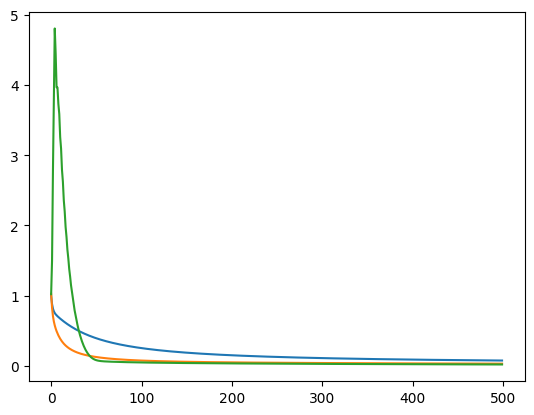

In [150]:
lmbda = 1e-2

theta0 = np.zeros(X_train_b.shape[1])
# Quelques pas à comparer
fixed_results = {}
theta = {}

for alpha in [0.01, 0.05, 0.1]: #se passe mal pour les grandes valeurs

    fixed_results[alpha], theta[alpha] = gradient_descent_fixed(objective, grad_objective, np.random.normal(scale = 1e-3, size=785),alpha, max_iter=500)

# TODO — tracer les historiques
# print(fixed_results)
absc = [k for k in range(500)]
for y in fixed_results : 
    plt.plot(absc, fixed_results[y])
plt.plot()

### 4.2 BONUS Règle d'Armijo

Pour $d_k=-\nabla f(\theta_k)$, on cherche $\alpha>0$ tel que
$$
f(\theta_k+\alpha d_k)
\leq
f(\theta_k)+c_1\alpha\nabla f(\theta_k)^\top d_k.
$$
Un backtracking part de $\alpha_0$ et remplace
$$
\alpha\leftarrow\rho\alpha,
\qquad 0<\rho<1,
$$
tant que la condition n'est pas satisfaite.

Programmez $\texttt{armijo\_step}$ puis une descente de gradient utilisant ce pas.



In [151]:
def armijo_step(f, gradf, theta, d,
                alpha0=1.0, rho=0.5, c1=1e-4,
                min_alpha=1e-12, f0=None, g0=None):
    # TODO
    return alpha, n_eval


def gradient_descent_armijo(f, gradf, theta0,
                            tol=1e-5, max_iter=1000,
                            alpha0=1.0, rho=0.5, c1=1e-4):
    # TODO
    return {
        "theta": theta, "f": np.array(hist_f), "grad_norm": np.array(hist_g),
        "alpha": np.array(hist_a), "iterations": k,
        "n_f_eval": n_f_eval, "time": elapsed
    }

    


### 4.3 BONUS Comparaison numérique
Comparez pas fixe et Armijo selon :
- nombre d'itérations ;
- nombre d'évaluations de $f$ ;
- temps CPU ;
- valeur finale de $f$ ;
- norme finale du gradient.


[]

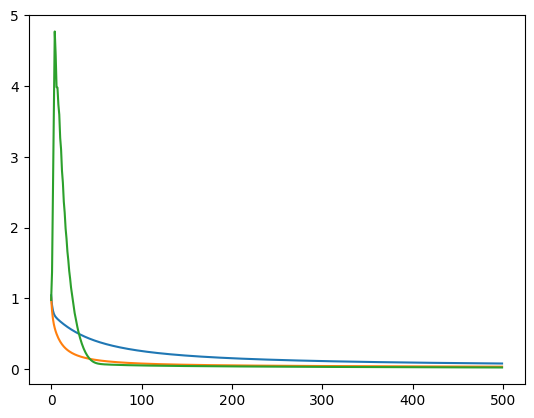

In [152]:
lmbda = 1e-2

theta0 = np.zeros(
    X_train_b.shape[1] 
)

# Quelques pas à comparer
fixed_results = {}
theta = {}

for alpha in [0.01, 0.05, 0.1]: #se passe mal pour les grandes valeurs

    fixed_results[alpha], theta[alpha] = gradient_descent_fixed(objective, grad_objective, np.random.normal(scale = 1e-3, size=785),alpha, max_iter=500)

# TODO — tracer les historiques
# print(fixed_results)
absc = [k for k in range(500)]
for y in fixed_results : 
    plt.plot(absc, fixed_results[y])
plt.plot()

## Avant l'évaluation du modèle, on retient le meilleur parametre $\theta^*$

In [153]:
theta_star = theta[0.1][-1]
print(theta_star)


[ 4.47431832e-04  2.79389065e-04 -5.00852913e-04  4.27320464e-04
  1.22299237e-03 -7.27460209e-04  3.38755141e-04  6.86352172e-05
  2.95802186e-04 -1.31740275e-03  9.88170979e-04 -8.75281876e-04
  3.63661168e-04 -2.80669155e-05 -6.27097769e-06  1.13536507e-03
 -1.00562663e-03 -2.83553823e-05 -3.19901486e-04 -7.83951417e-04
 -5.59415420e-04 -6.39539593e-04 -2.09407546e-04 -8.61467325e-04
 -2.46974085e-04 -9.14255020e-04 -4.77848664e-04  3.67587128e-04
  1.61564691e-04 -4.06464075e-04 -7.03391387e-05  3.36549230e-04
  7.35909473e-03 -4.47823757e-03 -7.72263784e-03  3.09582201e-02
  6.64989130e-02  7.90561443e-02 -4.67547133e-02 -6.65787608e-03
  1.06988030e-01 -4.76659912e-02 -4.12515595e-02 -6.05242411e-02
  8.98496829e-02 -5.28060563e-02  1.43610906e-01  1.33742452e-01
  1.18759292e-01  3.73118515e-02  3.39382912e-02 -3.06832083e-04
  1.38880274e-02  1.02168660e-02  3.23863307e-04 -1.11222920e-03
 -6.45540025e-04 -3.89436698e-04  5.03526536e-03  1.17656729e-02
  2.07600975e-03  1.01005

## 5. Évaluer et interpréter !!!
Calculez les probabilités et les classes sur le jeu de test, puis l'accuracy, la précision, le rappel et la matrice de confusion.



In [154]:
def predict_proba(theta, Xb):
    # TODO
    print(theta.shape, Xb.shape)
    res = []
    for i in range(Xb.shape[0]) : 
        res.append(sigmoid(np.dot(np.transpose(theta),Xb[i])))
    return res


def predict(theta, Xb, threshold=0.5):
    # TODO
    l = predict_proba(theta, Xb)
    res = []
    for i in range(len(l)):
        if l[i] >= threshold : 
            res.append(1)
        else : 
            res.append(0)
    return res

# TODO — métriques sur le test
def accuracy(theta, Xb,yb,threshold):
    s = 0
    pred = predict(theta,Xb,threshold)
    for i in range(len(Xb)):
        if pred[i] == yb[i] :
            s += 1
    s /= len(pred)
    print(s)
    return s


def precision(theta, Xb, yb, threshold):
    pred = predict(theta,Xb,threshold)
    res = 0
    for i in range(len(yb)):
        if pred[i] == 1 and yb[i] == 1 :
            res += 1
    res /= sum(pred)
    print(res)
    return res
            
def recall(theta, Xb, yb, threshold):
    pred = predict(theta,Xb,threshold)
    res = 0
    for i in range(len(yb)):
        if yb[i] == 1 :
            if pred[i]==1:
                res += 1
    res /= sum(yb)
    print(res)
    return res
     
def log_loss(theta, Xb, yb, threshold, lmbda=1e-2):
    w = theta[:-1]
    res = lmbda*np.linalg.norm(w)**2 /2 
    somme = 0
    pred = predict_proba(theta,Xb)
    for i in range(len(yb)):
        p_i = pred[i]
        somme -= (yb[i]*np.log(p_i)+(1-yb[i])*np.log(1-p_i))
    somme /= len(yb)
    res += somme
    print(res)
    return res
    

def matrice_confusion(theta, Xb, yb, threshold):
    pred = predict(theta,Xb,threshold)
    m=len(yb)
    n=len(pred)
    VP=0
    VN=0
    FP=0
    FN=0
    M=np.zeros((2,2))
    for i in range(m):
        if yb[i]==1:
            if pred[i]==1:
                VP=VP+1
            else:
                FN=FN+1
        else:
            if pred[i]==1:
                FP=FP+1
            else:
                VN=VN+1
    M[0,0]=VP
    M[1,1]=VN
    M[1,0]=FP
    M[0,1]=FN
    return M
accuracy(theta_star,X_train_b,y_train,0.5)
precision(theta_star,X_train_b,y_train,0.5)
recall(theta_star,X_train_b,y_train,0.5)
log_loss(theta_star,X_train_b,y_train,0.5)
matrice_confusion(theta_star,X_train_b,y_train,0.5)


(785,) (1400, 785)
0.8742857142857143
(785,) (1400, 785)
0.8850226928895613
(785,) (1400, 785)
0.8540145985401459
(785,) (1400, 785)
0.33831162348441485
(785,) (1400, 785)


array([[585., 100.],
       [ 76., 639.]])

### 5.2 Dessins mals classés

Affichez plusieurs dessins mal classés et les dessins dont la probabilité est la plus proche de $0.5$. 

Cherchez aussi un cas où le modèle se trompe avec une forte confiance.


(785,) (600, 785)
(785,) (600, 785)


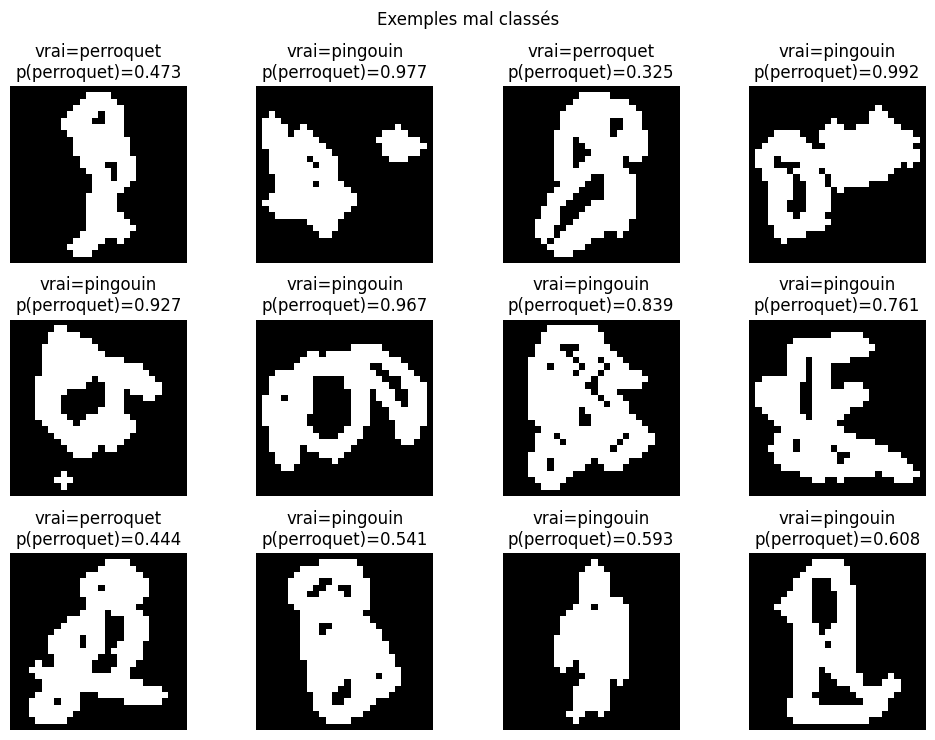

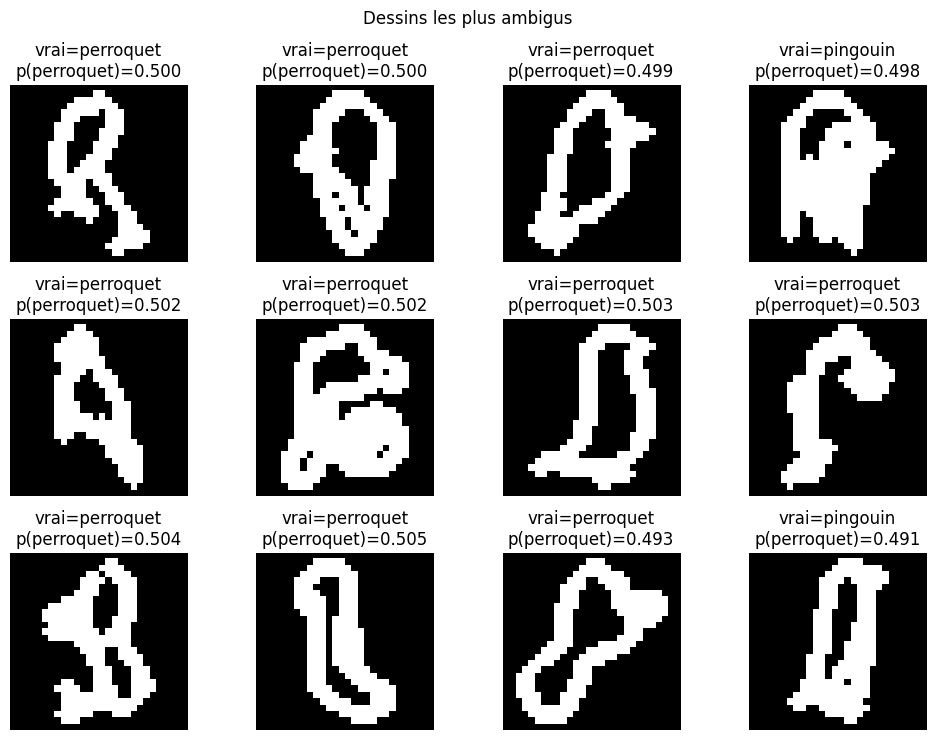

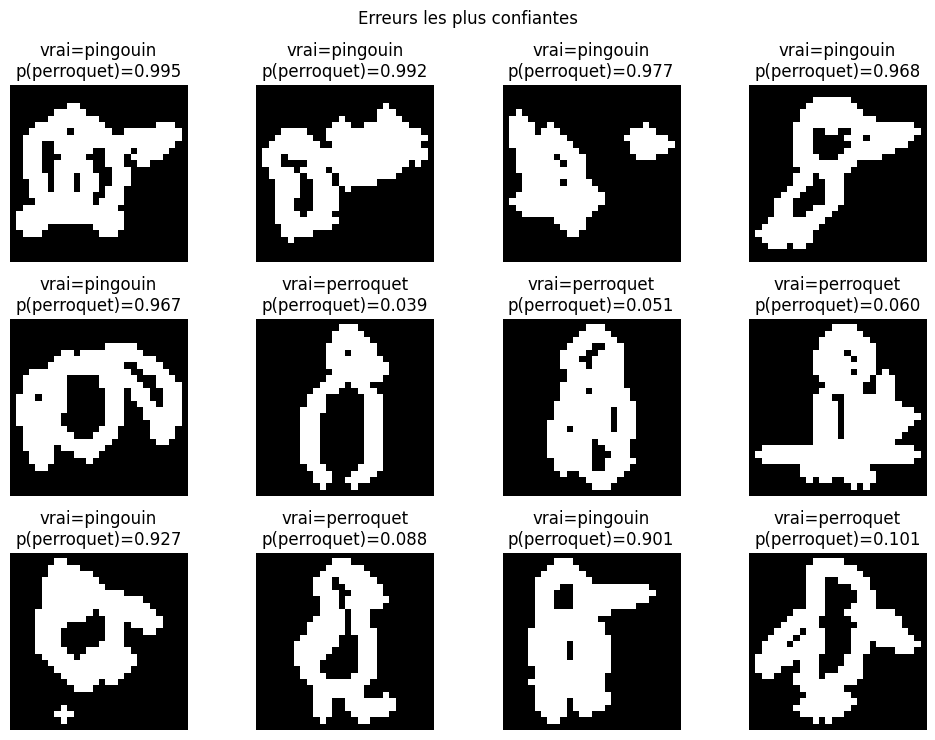

In [155]:
p_test = predict_proba(theta_star, X_test_b)
y_pred = predict(theta_star,X_test_b,0.5)

def show_indices(indices, title, max_n=12):
    indices = np.asarray(indices)[:max_n]
    n = len(indices)
    if n == 0:
        print(title, ": aucun exemple")
        return
    cols = 4
    rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5*rows))
    axes = np.atleast_1d(axes).ravel() 
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_test[i].reshape(28,28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"vrai={class_names[y_test[i]]}\np({class_names[1]})={p_test[i]:.3f}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()

wrong = np.where(y_pred != y_test)[0]
show_indices(wrong, "Exemples mal classés")

ambiguous = np.argsort(np.abs(np.array(p_test) - 0.5))
show_indices(ambiguous, "Dessins les plus ambigus")

if len(wrong):
    confident_wrong = wrong[np.argsort(-np.abs(np.array(p_test)[wrong]-0.5))]
    show_indices(confident_wrong, "Erreurs les plus confiantes")

### 5.3 Visualiser le vecteur $w$
Remettez $w\in\mathbb{R}^{784}$ sous forme d'une image $28\times28$. Les coefficients positifs favorisent la classe 1, les négatifs la classe 0. Comparez cette carte à $\bar x_1-\bar x_0$.


Effectifs : [1000 1000]
w_image : (28, 28)
x0_moy : (28, 28)
x1_moy : (28, 28)
diff : (28, 28)


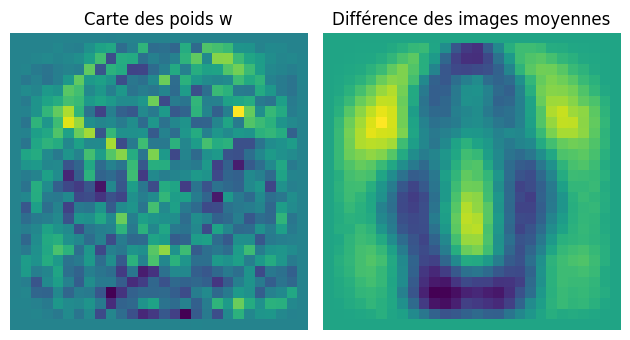

In [156]:
""" # Récupérer les poids sans le biais
w = theta_star[:-1]

# Transformer le vecteur en image 28 x 28
w_image = w.reshape(28, 28)

# Calculer la différence des images moyennes

x0_moy = Ximg[y==0].mean(axis = 0)
print(x0_moy.shape)
x1_moy = Ximg[y==1].mean(axis = 0)
diff = x1_moy-x0_moy
# Afficher les deux images
fig, axes = plt.subplots(1, 2)

axes[0].imshow(w_image)
axes[0].set_title("Carte des poids w")


axes[1].imshow(diff, cmap="gray")
axes[1].set_title("Différence des images moyennes")


plt.show()"""

# Recharger les images et les étiquettes correctes
Ximg, y, class_names = load_pair(PAIR, N_PER_CLASS)

# Vérifier les effectifs
print("Effectifs :", np.bincount(y))

# Récupérer les poids sans le biais
w = theta_star[:-1]

# Transformer les poids en image 28 x 28
w_image = w.reshape(28, 28)

x0_moy = Ximg[y == 0].mean(axis=0)
x1_moy = Ximg[y == 1].mean(axis=0)

diff = x1_moy - x0_moy

# Vérifier les dimensions
print("w_image :", w_image.shape)
print("x0_moy :", x0_moy.shape)
print("x1_moy :", x1_moy.shape)
print("diff :", diff.shape)

# Afficher les deux images
fig, axes = plt.subplots(1, 2)

axes[0].imshow(w_image)
axes[0].set_title("Carte des poids w")
axes[0].axis("off")

axes[1].imshow(diff)
axes[1].set_title("Différence des images moyennes")
axes[1].axis("off")

plt.tight_layout()
plt.show()



### 5.4 Comparaison à sklearn

utilisez `LogisticRegression` comme référence et comparez les performances. Les conventions de régularisation peuvent différer.


In [ ]:
#from sklearn.linear_model import LogisticRegression
#je recode par moi meme 

import numpy as np

# 1. Calculer les images moyennes à partir du jeu d'apprentissage
x0_moy = X_train[y_train == 0].mean(axis=0)
x1_moy = X_train[y_train == 1].mean(axis=0)

# 2. Classifieur par images moyennes
def predict_moyennes(X, x0_moy, x1_moy):

    predictions = []

    for x in X:
        d0 = np.linalg.norm(x - x0_moy)
        d1 = np.linalg.norm(x - x1_moy)

        if d0 <= d1:
            predictions.append(0)
        else:
            predictions.append(1)

    return np.array(predictions)


# 3. Prédictions du classifieur par images moyennes
y_pred_moy = predict_moyennes(X_test, x0_moy, x1_moy)

# 4. Accuracy du classifieur par images moyennes
accuracy_moy = np.mean(y_pred_moy == y_test)

# 5. Prédictions de notre régression logistique
p = sigmoid(X_test_b @ theta_star)
y_pred_perso = (p >= 0.5).astype(int)

# 6. Accuracy de notre modèle
accuracy_perso = np.mean(y_pred_perso == y_test)

# 7. Comparaison
print("Accuracy régression logistique :", accuracy_perso)
print("Accuracy images moyennes :", accuracy_moy)

Accuracy régression logistique : 0.8466666666666667
Accuracy images moyennes : 0.835


## 6. Défi — dessinez vous-même avec Qt

L'objectif est maintenant de tester le classifieur sur **vos propres dessins**.

Cette dernière partie reprend l'architecture du TP 2 :

- **`dessin_process.py`** contient les fonctions qui manipulent les tableaux NumPy ;
- **`dessin_viewer.py`** contient l'interface Qt et les interactions utilisateur ;

Les fonctions `paint_disk` et `paint_segment`, définies dans `dessin_process.py`,
sont à nouveau utilisées par `DrawingCanvas` dans `dessin_viewer.py` lorsqu'un utilisateur dessine à la souris.

#### Interface Qt

La fenêtre contient trois boutons :

- **Effacer** : remet le bitmap à zéro ;
- **Classifier** : appelle le classifieur défini dans le notebook ;
- **Sauver** : ouvre une boîte de dialogue Qt et enregistre le dessin en PNG.

L'interface ne connaît pas la régression logistique. Le notebook lui fournit une
fonction `classify_callback`.
Elle effectue le
prétraitement puis affiche la probabilité
\[
P(y=1\mid x)
\]
et la classe prédite.

Le modèle a été entraîné sur des images QuickDraw centrées et ramenées à
\(28\times 28\). Il faut donc appliquer **le même principe de prétraitement**
à un dessin personnel avant de le classer :

\[
\text{dessin personnel}
\longrightarrow
\text{détection de la zone dessinée}
\longrightarrow
\text{redimensionnement + recentrage}
\longrightarrow
28\times 28
\longrightarrow
\text{régression logistique}.
\]

La fonction `prepare_for_model` ci-dessous réutilise la fonction
`compute_centering_parameters` déjà employée dans `image_converter`.
Ainsi, les dessins QuickDraw et vos dessins personnels suivent la même
convention géométrique.
Si le chargement ne fonctionnement, il est possible de **dessiner dans un autre logiciel**, d'enregistrer le dessin en PNG, puis de
   le charger avec `load_png_as_bitmap` (du module `dessin_process`).
   
Vous devez tester au moins :

1. un dessin naturel de chaque classe ;
2. un dessin très minimaliste ;
3. un dessin volontairement ambigu ;
4. un dessin destiné à tromper le modèle avec une forte confiance.

Analysez chaque résultat : le dessin est-il correctement classé ? La
probabilité est-elle cohérente avec votre propre niveau d'hésitation ?


#### 6.1 importer prepare_for_model depuis le module `dessin_process` et compléter $\texttt{classify\_my\_bitmap}$ ci-dessous ainsi que $\texttt{\_paint\_at}$ depuis le module `dessin_viewer`

In [158]:
from dessin_process import prepare_for_model

In [134]:
def classify_my_bitmap(arr, theta=theta_star):
    """
    Classe un dessin personnel et affiche :
    - le dessin original ;
    - l'image 28 x 28 réellement donnée au modèle.
    """

    # -------------------------------------------------------------
    # 1. Prétraitement
    # -------------------------------------------------------------
    img28 = prepare_for_model(arr)

    # -------------------------------------------------------------
    # 2. Mise sous la forme attendue par le classifieur
    # -------------------------------------------------------------
    xb = add_bias(img28.reshape(1, -1))

    # -------------------------------------------------------------
    # 3. Probabilité et prédiction
    # -------------------------------------------------------------
    p = float(sigmoid(np.dot(theta, xb[0]))) #TODO!
    pred = int(p >= 0.5)

    # -------------------------------------------------------------
    # 4. Visualisation :
    #    dessin original / image vue par le modèle
    # -------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

    axes[0].imshow(
        arr,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title(
        "Ce que vous avez dessiné"
    )
    axes[0].axis("off")

    axes[1].imshow(
        img28,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[1].set_title(
        "Ce que voit le modèle"
    )
    axes[1].axis("off")

    fig.suptitle(
        f"Prédiction : {class_names[pred]} "
        f"— P({class_names[1]}) = {p:.3f}"
    )

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # 5. Informations renvoyées à l'interface Qt
    # -------------------------------------------------------------
    return {
        "label": class_names[pred],
        "probability": p,
        "class1_name": class_names[1],
    }

In [136]:
# ================================================================
# OUVRIR LA FENÊTRE QT
# ================================================================
# La commande %gui qt5 a été exécutée dans la cellule des imports.
# show_draw() crée la fenêtre, l'affiche et conserve QApplication.
#
# IMPORTANT : on conserve la fenêtre dans la variable pad afin qu'elle
# ne soit pas détruite par le ramasse-miettes Python.

pad = show_draw(
    size=280,
    brush=7,
    classify_callback=classify_my_bitmap,
    title=f"QuickDraw — {class_names[0]} / {class_names[1]}",
)


### Variante : charger un dessin PNG

Si le canevas interactif ne fonctionne pas :

1. dessinez l'objet sur un fond blanc ou noir ;
2. enregistrez-le au format PNG dans le dossier du notebook ;
3. chargez le fichier avec `load_png_as_bitmap` ;
4. envoyez le tableau obtenu à `classify_my_bitmap`.

`load_png_as_bitmap` **ne recentre pas** l'image : elle se contente de
la lire et de mettre les traits en blanc sur fond noir. Le recentrage est
effectué une seule fois, dans `prepare_for_model`, au moment de la
classification.


In [89]:
# Exemple avec une image externe :
# my_img = load_png_as_bitmap("mon_dessin.png")
# classify_my_bitmap(my_img)

### 6.1 Bilan

Revenez à votre réponse de la Question préambule section 1,
après avoir comparé avec les autres groupes vos accuracies et types d'erreurs. 
**Question**  Quel couple semble le mieux séparé par un modèle linéaire ?
